
# Training a Decision Tree or a Random Forest on a classification problem, and compare the latter with using adaBoost

**Author: Pr Fabien MOUTARDE, Center for Robotics, MINES ParisTech, PSL Université Paris**


## 1. Decision Trees with SciKit-Learn on a very simple dataset

**We will first work on a very simple and classic dataset: Iris, which is a classification problem corresponding to determination of iris flower sub-species based on a few geometric characteristics of the flower.**

**Please FIRST READ the [*Iris DATASET DESCRIPTION*](http://scikit-learn.org/stable/auto_examples/datasets/plot_iris_dataset.html#sphx-glr-auto-examples-datasets-plot-iris-dataset-py).**
In this classification problem, there are 3 classes, with a total of 150 examples (each one with 4 input). Please **now execute the code cell below to load and view the dataset**.


In [1]:
import numpy as np

from matplotlib import pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn import preprocessing
from sklearn.preprocessing import StandardScaler

# Load Iris classification dataset
from sklearn.datasets import load_iris
iris = load_iris()

# Print all 150 examples
print("(Number_of_examples, example_size) = " , iris.data.shape, "\n")
for i in range(0, 150) :
    print('Input = ', iris.data[i], ' , Label = ', iris.target[i] )


(Number_of_examples, example_size) =  (150, 4) 

Input =  [5.1 3.5 1.4 0.2]  , Label =  0
Input =  [4.9 3.  1.4 0.2]  , Label =  0
Input =  [4.7 3.2 1.3 0.2]  , Label =  0
Input =  [4.6 3.1 1.5 0.2]  , Label =  0
Input =  [5.  3.6 1.4 0.2]  , Label =  0
Input =  [5.4 3.9 1.7 0.4]  , Label =  0
Input =  [4.6 3.4 1.4 0.3]  , Label =  0
Input =  [5.  3.4 1.5 0.2]  , Label =  0
Input =  [4.4 2.9 1.4 0.2]  , Label =  0
Input =  [4.9 3.1 1.5 0.1]  , Label =  0
Input =  [5.4 3.7 1.5 0.2]  , Label =  0
Input =  [4.8 3.4 1.6 0.2]  , Label =  0
Input =  [4.8 3.  1.4 0.1]  , Label =  0
Input =  [4.3 3.  1.1 0.1]  , Label =  0
Input =  [5.8 4.  1.2 0.2]  , Label =  0
Input =  [5.7 4.4 1.5 0.4]  , Label =  0
Input =  [5.4 3.9 1.3 0.4]  , Label =  0
Input =  [5.1 3.5 1.4 0.3]  , Label =  0
Input =  [5.7 3.8 1.7 0.3]  , Label =  0
Input =  [5.1 3.8 1.5 0.3]  , Label =  0
Input =  [5.4 3.4 1.7 0.2]  , Label =  0
Input =  [5.1 3.7 1.5 0.4]  , Label =  0
Input =  [4.6 3.6 1.  0.2]  , Label =  0
Input = 

**Building, training and evaluating a simple Decision Tree classifier**

The SciKit-learn class for Decision Tree classifiers is sklearn.tree.DecisionTreeClassifier.

**Please FIRST READ (and understand!) the [*DecisionTreeClassifier DOCUMENTATION*](http://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html#sklearn.tree.DecisionTreeClassifier) to understand all parameters of the contructor.**

**You can then begin by running the code block below, in which default set of parameter values has been used.** If graphical view works, look at the structure of the learnt decision tree.

**Then, check the influence of MAIN parameters for Decision Tree classifier, i.e.:**
 - **homegeneity criterion ('gini' or 'entropy')**
 - **max_depth**
 - **min_samples_split**

NB : Note that post-training *PRUNING* IS unfortunately *NOT* implemented in SciKit-Learn Decision-Trees :(

DecisionTreeClassifier(max_depth=6, min_samples_split=12)
Acuracy (on test set) =  0.9333333333333333
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        14
           1       0.89      0.94      0.91        17
           2       0.92      0.86      0.89        14

    accuracy                           0.93        45
   macro avg       0.94      0.93      0.93        45
weighted avg       0.93      0.93      0.93        45


 CONFUSION MATRIX
[[14  0  0]
 [ 0 16  1]
 [ 0  2 12]]


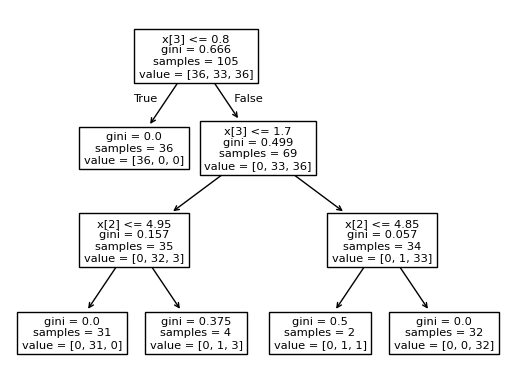

In [3]:
from sklearn.model_selection import train_test_split

# Split dataset into training and test part
X_train, X_test, y_train, y_test = train_test_split(iris.data, iris.target, test_size=0.3)

# Learn a Decision Tree
from sklearn import tree
clf = tree.DecisionTreeClassifier(criterion='gini', splitter='best', max_depth=6,
                                  min_samples_split=12, min_samples_leaf=1,
                                  min_weight_fraction_leaf=0.0, max_features=None,
                                  random_state=None, max_leaf_nodes=None,
                                  min_impurity_decrease=0.0, class_weight=None) # if min_impurity_split doesn't work use min_impurity_decrease
clf = clf.fit(X_train, y_train)

# Graphical view of learnt Decision Tree
tree.plot_tree(clf)

# Evaluate acuracy on test data
print(clf)
score = clf.score(X_test, y_test)
print("Acuracy (on test set) = ", score)
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
y_true, y_pred = y_test, clf.predict(X_test)
print( classification_report(y_true, y_pred) )
print("\n CONFUSION MATRIX")
print( confusion_matrix(y_true, y_pred) )

## 2. Decision Trees on a  MORE REALISTIC DATASET: HANDWRITTEN DIGITS

**Please FIRST READ the [*Digits DATASET DESCRIPTION*](http://scikit-learn.org/stable/auto_examples/datasets/plot_digits_last_image.html#sphx-glr-auto-examples-datasets-plot-digits-last-image-py).**

In this classification problem, there are 10 classes, with a total of 1797 examples (each one being a 64D vector corresponding to an 8x8 pixmap). Please **now execute code cell below to load the dataset, visualize a typical example, and train a Desicion Tree on it**.
The original code uses a **voluntarily SUBOPTIMAL set of learning hyperparameters values, which reaches ~66% test acuracy. Try to play with them in order to improve acuracy.**


Number_of-examples =  1797

 Plot of first example


<Figure size 640x480 with 0 Axes>

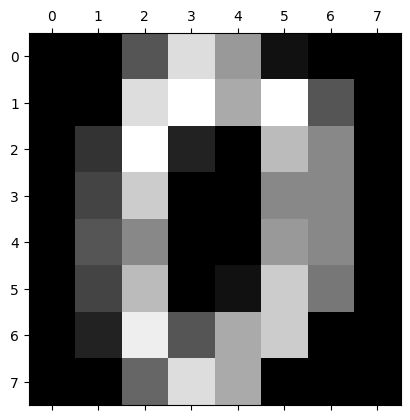

DecisionTreeClassifier(max_depth=15, min_samples_split=4)
Acuracy (on test set) =  0.8231368186874305
              precision    recall  f1-score   support

           0       0.90      0.92      0.91        89
           1       0.84      0.85      0.84        97
           2       0.79      0.82      0.80        93
           3       0.87      0.78      0.82        94
           4       0.65      0.82      0.72        76
           5       0.86      0.90      0.88        82
           6       0.96      0.84      0.90        96
           7       0.87      0.76      0.81        86
           8       0.73      0.84      0.78        85
           9       0.80      0.73      0.77       101

    accuracy                           0.82       899
   macro avg       0.83      0.82      0.82       899
weighted avg       0.83      0.82      0.82       899


 CONFUSION MATRIX
[[82  0  4  0  1  1  0  0  0  1]
 [ 0 82  1  3  2  1  0  1  4  3]
 [ 3  2 76  2  1  1  1  0  6  1]
 [ 0  1  5 73  5  0  

In [ ]:
from sklearn.datasets import load_digits
digits = load_digits()
n_samples = len(digits.images)
print("Number_of-examples = ", n_samples)

import matplotlib.pyplot as plt
print("\n Plot of first example")
plt.gray()
plt.matshow(digits.images[0])
plt.show()

# Flatten the images, to turn data in a (samples, feature) matrix:
data = digits.images.reshape((n_samples, -1))

# Split dataset into training and test part
X = data
y = digits.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=0)

# Create and train a Decision Tree Classifier
clf = tree.DecisionTreeClassifier(criterion='gini', splitter='best', max_depth=15,
                                  min_samples_split=4, min_samples_leaf=1,
                                  min_weight_fraction_leaf=0.0, max_features=None,
                                  random_state=None, max_leaf_nodes=None,
                                  min_impurity_decrease=0.0, class_weight=None) # if min_impurity_split doesn't work use min_impurity_decrease
clf = clf.fit(X_train, y_train)


# Evaluate acuracy on test data
print(clf)
score = clf.score(X_test, y_test)
print("Acuracy (on test set) = ", score)
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
y_true, y_pred = y_test, clf.predict(X_test)
print( classification_report(y_true, y_pred) )
print("\n CONFUSION MATRIX")
print( confusion_matrix(y_true, y_pred) )


__Question: According to the confusion matrices, what digits are the most confused with each other?__

__Answer:__

> _Your answer:_
>
> 

**Finally, find somewhat optimized values for the set of 3 main hyper-parameters for DecisionTree learning, by using GRID-SEARCH WITH CROSS-VALIDATION**.

__Complete the code in the cell below:__

In [13]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report

# Grid-search the 3 main DecisionTree hyper-parameters with 5-fold cross-validation:
#     criterion ('gini' / 'entropy'), max_depth, min_samples_split
# Then print: best_params_, best_score_, the TEST accuracy of best_estimator_,
# and a classification_report.
# Target to beat: ~0.80 test accuracy (the untuned tree above sits around 0.66).

### YOUR CODE HERE ###

parameters = {'criterion':('gini', 'entropy'), 'max_depth':[3,5, 8, 12, 15, 18, 20, 25], 'min_samples_split':[2, 4, 8]}
model = tree.DecisionTreeClassifier()
grid_search = GridSearchCV(model, parameters, cv=5)
grid_search.fit(X_train, y_train)

print(grid_search.best_params_)        # which combination won
print(grid_search.best_score_)         # its mean score over the 5 folds


### END OF YOUR CODE ###


{'criterion': 'entropy', 'max_depth': 8, 'min_samples_split': 4}
0.8207262569832402


__Question: What best value have you managed to reach for TEST accuracy of your DecisionTree after you properly gridSearched its hyper-parameters using CrossValidation?__

__Answer:__

> _Your answer:_
>
> 

## 3. Building, training and evaluating a Random Forest classifier

The SciKit-learn class for Random Forest classifiers is sklearn.ensemble.RandomForestClassifier.

**Please FIRST READ (and understand!) the [*RandomForestClassifier DOCUMENTATION*](http://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html) to understand all parameters of the contructor.**

**Then you can begin by running the code block below, in which default set of parameter values has been used.** As you will see, a RandomForest (even rather small) can easily outperform single Decision Tree.

**Then, check the influence of MAIN parameters for Random Forest classifier, i.e.:**
 - **n_estimators (number of trees in forest)**
 - **max_depth**
 - **max_features (max number of features used in each tree)**


In [14]:
from sklearn.ensemble import RandomForestClassifier

# Create and train a Random Forest classifier
clf = RandomForestClassifier(n_estimators=10, criterion='gini', max_depth=10,
                             min_samples_split=3, min_samples_leaf=1,
                             min_weight_fraction_leaf=0.0, max_features="sqrt", # "sqrt" means that each split considers sqrt(number of features).
                             max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=True,
                             oob_score=False, n_jobs=1, random_state=None,
                             verbose=0, warm_start=False, class_weight=None)
clf = clf.fit(X_train, y_train)
print("n_estimators=", clf.n_estimators, " max_depth=",clf.max_depth,
      "max_features=", clf.max_features)

# Evaluate acuracy on test data
print(clf)
score = clf.score(X_test, y_test)
print("Acuracy (on test set) = ", score)
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
y_true, y_pred = y_test, clf.predict(X_test)
print( classification_report(y_true, y_pred) )
print("\n CONFUSION MATRIX")
print( confusion_matrix(y_true, y_pred) )


n_estimators= 10  max_depth= 10 max_features= sqrt
RandomForestClassifier(max_depth=10, min_samples_split=3, n_estimators=10,
                       n_jobs=1)
Acuracy (on test set) =  0.9377085650723026
              precision    recall  f1-score   support

           0       0.98      0.99      0.98        89
           1       0.91      0.97      0.94        97
           2       0.96      0.99      0.97        93
           3       0.93      0.90      0.92        94
           4       0.95      0.95      0.95        76
           5       0.93      0.99      0.96        82
           6       0.99      0.97      0.98        96
           7       0.89      0.95      0.92        86
           8       0.91      0.80      0.85        85
           9       0.93      0.87      0.90       101

    accuracy                           0.94       899
   macro avg       0.94      0.94      0.94       899
weighted avg       0.94      0.94      0.94       899


 CONFUSION MATRIX
[[88  0  0  0  1  0

**Finally, find somewhat optimized values the set of 3 main hyper-parameters for RandomForest, by using CROSS-VALIDATION** (see cross-validation example from the code above). 

__Put the code in the cell below:__

In [ ]:
# Same exercise for the RandomForest. Main hyper-parameters:
#     n_estimators, max_depth, max_features
# Reuse the GridSearchCV pattern you just wrote.
# Target to beat: ~0.955 test accuracy.
#
# Think before you run: the grid is a product, so 5 x 5 x 5 x 5 folds = 625 fits.
# Keep the lists short and pass n_jobs=-1.

### YOUR CODE HERE ###


### END OF YOUR CODE ###


__Question: What best value have you managed to reach for TEST accuracy of your RandomForest after you properly gridSearched its hyper-parameters using CrossValidation?__

__Answer:__

> _Your answer:_
>
> 

## 3. Building, training and evaluating an AdaBoost classifier

The SciKit-learn class for adaBoost is sklearn.ensemble.AdaBoostClassifier.

**Please FIRST READ (and understand!) the [*AdaBoostClassifier DOCUMENTATION*](http://scikit-learn.org/stable/modules/generated/sklearn.ensemble.AdaBoostClassifier.html#sklearn.ensemble.AdaBoostClassifier) to understand all parameters of the contructor.**

**Then begin by running the code block below, in which a default set of parameter values has been used.**

**Then, check the influence of MAIN parameters for adaBoost classifier, i.e.:**
 - **base_estimator (ie type of Weak Classifier/Learner)**
 - **n_estimators (number of boosting iterations, and therefore also number of weak classifiers)**
 - algorithm

**Finally, check which other types of classifiers can be used as Weak Classifier with the adaBoost implementation of SciKit-Learn.**
NB: in principle it is possible to use MLP classifiers as weak classifiers, but not with SciKit-learn implementation of MLPClassifier (because weighting of examples is not handled by its implementation).

(Teacher version) -- It also supports :

- RandomForestClassifier
- LogisticRegression

In [ ]:
from sklearn.ensemble import AdaBoostClassifier

# Create and train an adaBoost classifier using SMALL Decision Trees as weak classifiers
weak_learner = tree.DecisionTreeClassifier(max_depth=6)
clf = AdaBoostClassifier(weak_learner, n_estimators=15, learning_rate=1.0, algorithm='SAMME',
                         random_state=None)
clf = clf.fit(X_train, y_train)
print("Weak_learners:", clf.estimators_)
print("Weights of weak classifiers: ", clf.estimator_weights_)

# Plot training curves (error = f(iterations))
n_iter = clf.n_estimators
from sklearn.metrics import zero_one_loss
ada_train_err = np.zeros((clf.n_estimators,))
for i, y_pred in enumerate(clf.staged_predict(X_train)):
    ada_train_err[i] = zero_one_loss(y_pred, y_train)
ada_test_err = np.zeros((clf.n_estimators,))
for i, y_pred in enumerate(clf.staged_predict(X_test)):
    ada_test_err[i] = zero_one_loss(y_pred, y_test)
fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(np.arange(n_iter) + 1, ada_train_err,
        label='Training Error',
        color='green')
ax.plot(np.arange(n_iter) + 1, ada_test_err,
        label='Test Error',
        color='orange')
ax.set_ylim((0.0, 0.5))
ax.set_xlabel('boosting iterations')
ax.set_ylabel('error rate')
leg = ax.legend(loc='upper right', fancybox=True)
plt.show()

# Evaluate acuracy on test data
print("n_estimators=", clf.n_estimators)
score = clf.score(X_test, y_test)
print("Acuracy (on test set) = ", score)
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
y_true, y_pred = y_test, clf.predict(X_test)
print( classification_report(y_true, y_pred) )
print("\n CONFUSION MATRIX")
print( confusion_matrix(y_true, y_pred) )

__Question:__ Looking at the training curves, you can see that **training error goes down to zero rather quickly, but that test_error still continues, after training error is zero, to diminish with increasing iterations**. __Is it normal, and why?__ (check the course!)

__Answer:__

> _Your answer:_
>
> 

**Now, for the case of _DecisionTree_ weak classifiers, find somewhat optimized values of (max_depth, n_estimators) by using CROSS-VALIDATION.** __Put the code below:__

In [ ]:
# TIP: to tune a hyper-parameter OF THE WEAK LEARNER, prefix it:
#      estimator__<param_name>        -> current scikit-learn
#      base_estimator__<param_name>   -> scikit-learn < 1.2
#
# Grid-search (max_depth of the weak tree, n_estimators) for AdaBoost.
# Target to beat: ~0.96 test accuracy.

### YOUR CODE HERE ###


### END OF YOUR CODE ###


__Question: What best value have you managed to reach for TEST accuracy of your AdaboostClassifier after you properly gridSearched its hyper-parameters using CrossValidation?__

__Answer:__

> _Your answer:_
>
> 